# R2-A2-S8 · Informe de resultados de tratamiento de imagen
**Percepción Computacional · Especialización en Inteligencia Artificial · Semana 8**

**Objeto analizado:** loción hidratante CeraVe (botella con dispensador)  
**Dispositivo de captura:** HONOR CLK-LX3  
**Herramientas:** Python, OpenCV, NumPy, pandas y Matplotlib (Google Colab)

**Propósito.** Evaluar la calidad de cinco fotografías del mismo objeto tomadas bajo condiciones distintas, medirlas con métricas simples y comprobar con datos si un tratamiento básico mejora el problema identificado en una de ellas.

## 0. Configuración

In [1]:
import os, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
os.makedirs('resultados', exist_ok=True)

# Imágenes del conjunto (nombre en el informe -> archivo)
ARCHIVOS = {
    'Referencia': 'referencia.jpg',
    'Oscura': 'oscura.jpg',
    'Desenfocada': 'desenfocada.jpg',
    'Fondo complejo': 'fondo.jpg',
    'Otra perspectiva': 'angulo.jpg',
}

# Objeto fotografiado (se usa en los títulos)
OBJETO = 'Crema'
print('Configuración lista.')

Configuración lista.


## 1. Carga de las cinco imágenes

In [2]:
try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

faltan = [f for f in ARCHIVOS.values() if not os.path.exists(f)]
if faltan and EN_COLAB:
    print('Selecciona estos archivos para subir:', faltan)
    files.upload()
elif faltan:
    print('Fuera de Colab: coloca los archivos en la carpeta actual.')

faltan = [f for f in ARCHIVOS.values() if not os.path.exists(f)]
assert not faltan, f'Faltan archivos o tienen otro nombre: {faltan}'

imagenes = {}
for nombre, ruta in ARCHIVOS.items():
    img = cv2.imread(ruta)
    assert img is not None, f'No se pudo leer {ruta}'
    imagenes[nombre] = img
print('Imágenes cargadas:', list(imagenes))

Imágenes cargadas: ['Referencia', 'Oscura', 'Desenfocada', 'Fondo complejo', 'Otra perspectiva']


### 1.1 Condiciones de captura (EXIF)
Dispositivo y parámetros de exposición registrados por la cámara en cada fotografía.

In [3]:
def exif_info(ruta):
    try:
        ex = Image.open(ruta)._getexif() or {}
        d = {TAGS.get(k, k): v for k, v in ex.items()}
    except Exception:
        d = {}
    disp = f"{d.get('Make', '')} {d.get('Model', '')}".strip() or 'N/D'
    return {
        'Dispositivo': disp,
        'Exposición (s)': str(d.get('ExposureTime', 'N/D')),
        'ISO': str(d.get('ISOSpeedRatings', d.get('PhotographicSensitivity', 'N/D'))),
        'Apertura (f)': str(d.get('FNumber', 'N/D')),
        'Fecha captura': str(d.get('DateTimeOriginal', 'N/D')),
        'Peso original (KB)': round(os.path.getsize(ruta) / 1024, 1),
    }

df_exif = pd.DataFrame({n: exif_info(r) for n, r in ARCHIVOS.items()}).T
df_exif.to_csv('resultados/00_condiciones_captura.csv', encoding='utf-8-sig')
df_exif

,Dispositivo,Exposición (s),ISO,Apertura (f),Fecha captura,Peso original (KB)
Referencia,HONOR CLK-LX3,0.01,4359,1.75,2026:10:17 08:47:37,3154.1
Oscura,HONOR CLK-LX3,0.06,18944,1.75,2026:10:17 08:47:39,3754.6
Desenfocada,HONOR CLK-LX3,0.06,1006,1.75,2026:10:17 08:49:29,4776.6
Fondo complejo,HONOR CLK-LX3,0.01,5056,1.75,2026:10:17 08:51:19,4850.1
Otra perspectiva,HONOR CLK-LX3,0.04,913,1.75,2026:10:17 08:53:35,3145.0


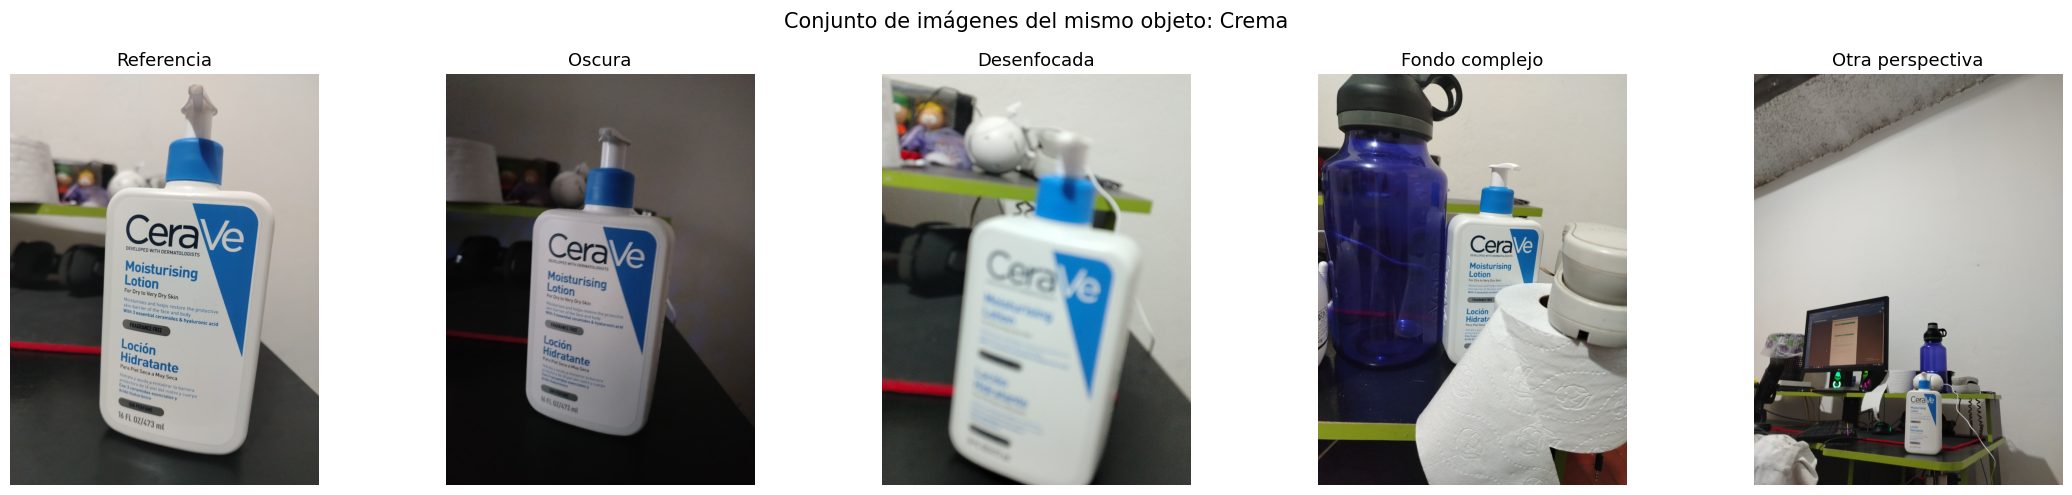

In [4]:
fig, axs = plt.subplots(1, 5, figsize=(22, 5))
for ax, (n, img) in zip(axs, imagenes.items()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(n, fontsize=13)
    ax.axis('off')
plt.suptitle(f'Conjunto de imágenes del mismo objeto: {OBJETO}', fontsize=15)
plt.tight_layout()
plt.savefig('resultados/01_conjunto_imagenes.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Diagnóstico de las imágenes

Para cada imagen se calcularon las métricas de la guía (brillo, contraste, nitidez y resolución) y algunas métricas adicionales, cuya utilidad se justifica a continuación.

| Métrica | Cálculo | Utilidad |
|---|---|---|
| Brillo | media de la imagen en gris | detectar sub o sobreexposición |
| Contraste | desviación estándar del gris | separación entre zonas claras y oscuras |
| Nitidez | varianza del Laplaciano | respuesta a bordes finos; baja si hay desenfoque |
| Resolución | ancho × alto | tamaño de entrada disponible |
| Nitidez (800 px) | Laplaciano tras reescalar a 800 px de ancho | el Laplaciano depende del tamaño; así se compara en igualdad de condiciones |
| % píxeles oscuros | píxeles con gris < 50 | cuantifica la subexposición |
| % píxeles saturados | píxeles con gris ≥ 250 | detecta zonas quemadas |
| Rango dinámico | percentil 99 − percentil 1 | amplitud real de intensidades usadas |
| Densidad de bordes | % de píxeles de borde (Canny) | indicador de textura y complejidad del fondo |
| Ruido estimado | desviación de (gris − gris con filtro mediana 3×3) | evita que “más nitidez” sea solo ruido amplificado |

In [5]:
def metricas(img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    alto, ancho = gris.shape
    g800 = cv2.resize(gris, (800, int(alto * 800 / ancho)), interpolation=cv2.INTER_AREA)
    ruido = (gris.astype(np.float32) - cv2.medianBlur(gris, 3).astype(np.float32)).std()
    return {
        'Ancho': ancho,
        'Alto': alto,
        'Canales': img.shape[2] if img.ndim == 3 else 1,
        'Resolución': f'{ancho}x{alto}',
        'Megapíxeles': round(ancho * alto / 1e6, 2),
        'Brillo': float(gris.mean()),
        'Contraste': float(gris.std()),
        'Nitidez': float(cv2.Laplacian(gris, cv2.CV_64F).var()),
        'Nitidez (800 px)': float(cv2.Laplacian(g800, cv2.CV_64F).var()),
        '% píxeles oscuros (<50)': float((gris < 50).mean() * 100),
        '% píxeles saturados (>=250)': float((gris >= 250).mean() * 100),
        'Rango dinámico (p99-p1)': float(np.percentile(gris, 99) - np.percentile(gris, 1)),
        'Densidad de bordes (%)': float((cv2.Canny(gris, 100, 200) > 0).mean() * 100),
        'Ruido estimado': float(ruido),
    }

met = {n: metricas(img) for n, img in imagenes.items()}

# Problema identificado en cada imagen (métricas + inspección visual)
diagnostico = {
    'Referencia': ('Ninguno (imagen de control)', 'Sí'),
    'Oscura': ('Subexposición: brillo bajo y alto porcentaje de píxeles oscuros', 'No'),
    'Desenfocada': ('Pérdida de enfoque en el objeto', 'No'),
    'Fondo complejo': ('Objeto rodeado de otros elementos que lo ocluyen parcialmente', 'Parcial'),
    'Otra perspectiva': ('Objeto pequeño y lejano dentro del encuadre', 'Parcial'),
}

df = pd.DataFrame(met).T
df['Problema identificado'] = [diagnostico[n][0] for n in df.index]
df['¿Adecuada?'] = [diagnostico[n][1] for n in df.index]
df.to_csv('resultados/02_tabla_diagnostico.csv', encoding='utf-8-sig')
df.round(2)

,Ancho,Alto,Canales,Resolución,Megapíxeles,Brillo,Contraste,Nitidez,Nitidez (800 px),% píxeles oscuros (<50),% píxeles saturados (>=250),Rango dinámico (p99-p1),Densidad de bordes (%),Ruido estimado,Problema identificado,¿Adecuada?
Referencia,3000,4000,3,3000x4000,12.0,134.688676,68.42222,15.316764,276.627525,15.3129,0.066642,202.0,0.506475,0.709785,Ninguno (imagen de control),Sí
Oscura,3000,4000,3,3000x4000,12.0,64.63444,49.3673,20.271996,62.397946,40.980917,0.0,171.0,0.194475,1.249767,Subexposición: brillo bajo y alto porcentaje d...,No
Desenfocada,3000,4000,3,3000x4000,12.0,145.101238,71.153982,123.207409,354.714147,17.335333,0.672342,234.0,4.910275,3.14969,Pérdida de enfoque en el objeto,No
Fondo complejo,3000,4000,3,3000x4000,12.0,126.982799,76.93012,104.41475,197.484487,31.156583,0.033808,216.0,0.532767,2.788095,Objeto rodeado de otros elementos que lo ocluy...,Parcial
Otra perspectiva,3000,4000,3,3000x4000,12.0,147.476879,62.150909,14.778693,129.267797,12.252367,0.007067,203.0,0.311375,0.667204,Objeto pequeño y lejano dentro del encuadre,Parcial


### Observaciones del diagnóstico

- **Referencia:** brillo de 134.7, contraste de 68.4 y solo 15.3 % de píxeles oscuros. Sirve como punto de comparación para las demás imágenes.
- **Oscura:** brillo de 64.6 (menos de la mitad de la referencia), contraste de 49.4 y 41.0 % de píxeles oscuros. Es el problema más claro y medible del conjunto.
- **Desenfocada:** el objeto se ve borroso a simple vista, pero la nitidez global (123.2) resultó mayor que la de la referencia (15.3). El ruido estimado (3.15) y la densidad de bordes (4.91 %) también son mayores, lo que indica que el Laplaciano global está midiendo detalle fino del entorno y no solo el enfoque del objeto. En esta imagen la métrica no refleja el desenfoque de forma confiable.
- **Fondo complejo:** brillo similar al de la referencia (127.0) y el mayor contraste del conjunto (76.9). El objeto comparte el encuadre con otros elementos; este problema se identificó visualmente porque las métricas globales casi no lo detectan.
- **Otra perspectiva:** las métricas globales cambian poco; el cambio de punto de vista deja al objeto pequeño dentro del encuadre.

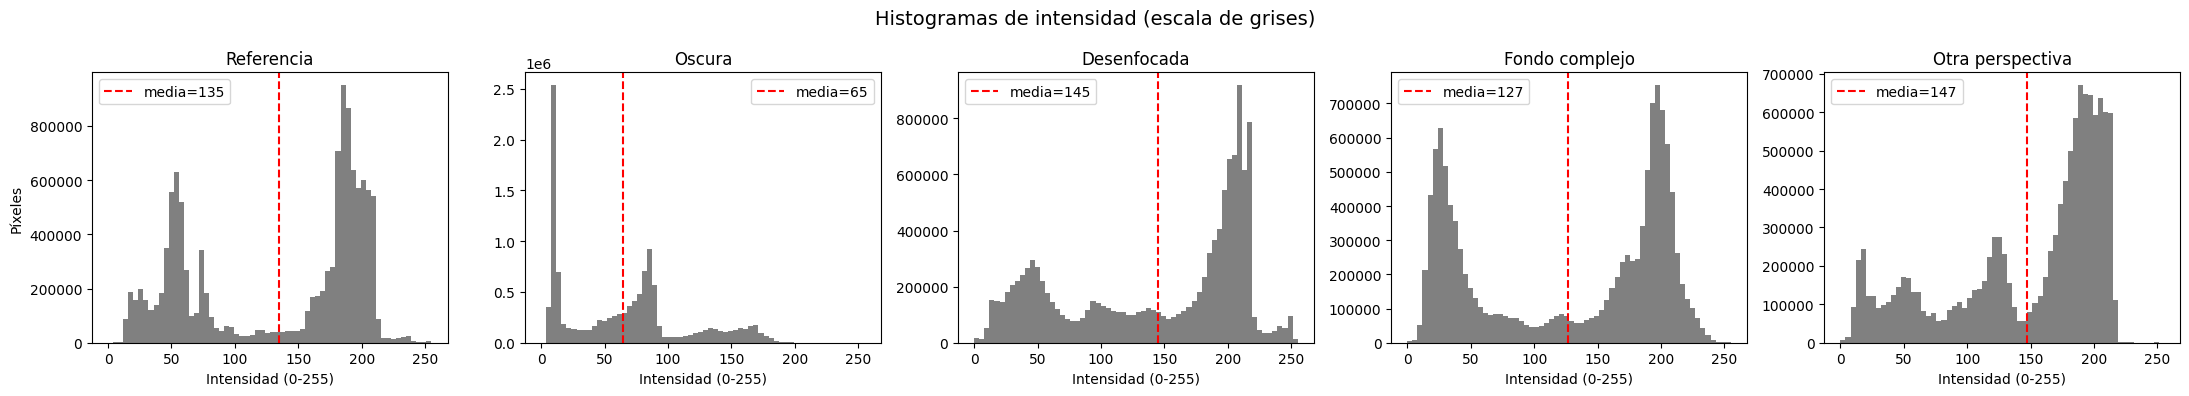

In [6]:
fig, axs = plt.subplots(1, 5, figsize=(22, 4))
for ax, (n, img) in zip(axs, imagenes.items()):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ax.hist(g.ravel(), bins=64, range=(0, 255), color='gray')
    ax.axvline(g.mean(), color='red', linestyle='--', label=f'media={g.mean():.0f}')
    ax.set_title(n)
    ax.set_xlabel('Intensidad (0-255)')
    ax.legend()
axs[0].set_ylabel('Píxeles')
plt.suptitle('Histogramas de intensidad (escala de grises)', fontsize=14)
plt.tight_layout()
plt.savefig('resultados/03_histogramas.png', dpi=150, bbox_inches='tight')
plt.show()

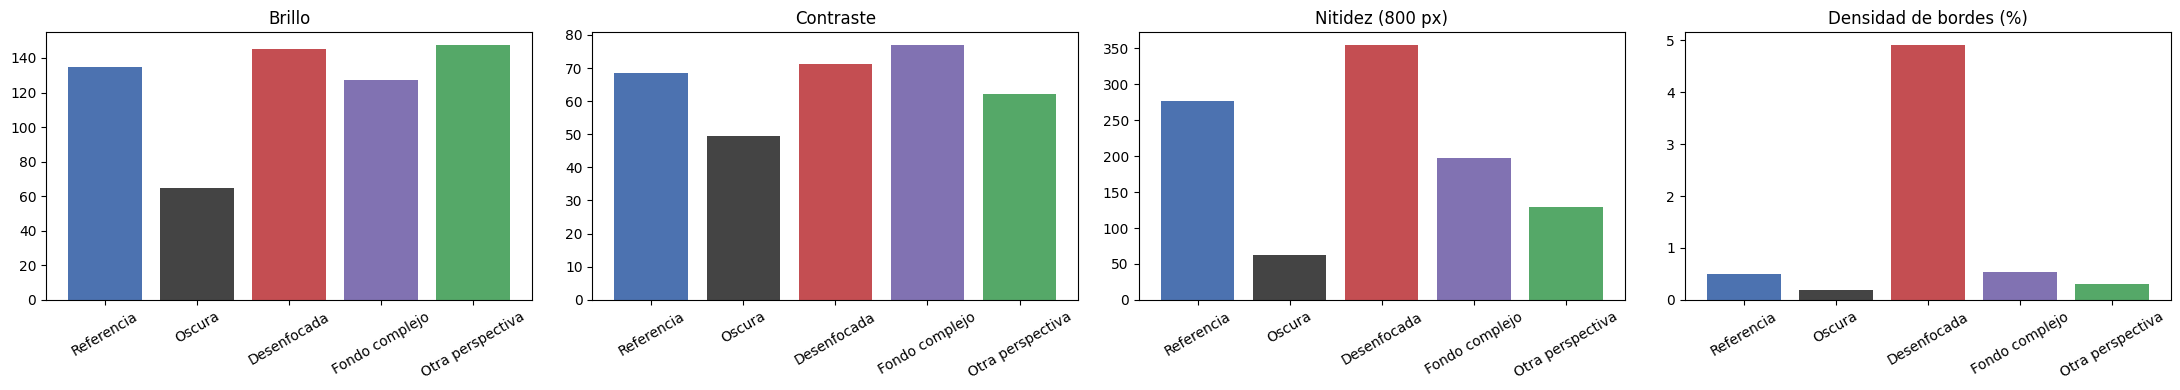

In [7]:
cols = ['Brillo', 'Contraste', 'Nitidez (800 px)', 'Densidad de bordes (%)']
fig, axs = plt.subplots(1, 4, figsize=(22, 4))
for ax, c in zip(axs, cols):
    ax.bar(df.index, df[c].astype(float), color=['#4c72b0', '#444', '#c44e52', '#8172b2', '#55a868'])
    ax.set_title(c)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('resultados/04_metricas_comparadas.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Formato y tamaño de archivo (JPG vs PNG)
Se guardó la imagen de referencia en JPG (calidad 90), en PNG y en JPG de calidad 50 para comparar el tamaño del archivo y la pérdida de información respecto al original.

In [8]:
IMAGEN_FORMATO = 'Referencia'
orig = imagenes[IMAGEN_FORMATO]

cv2.imwrite('comparacion.jpg', orig, [cv2.IMWRITE_JPEG_QUALITY, 90])
cv2.imwrite('comparacion.png', orig)
cv2.imwrite('comparacion_q50.jpg', orig, [cv2.IMWRITE_JPEG_QUALITY, 50])

filas = []
for etiqueta, ruta in [('JPG (calidad 90)', 'comparacion.jpg'),
                       ('PNG', 'comparacion.png'),
                       ('JPG (calidad 50)', 'comparacion_q50.jpg')]:
    dec = cv2.imread(ruta)
    h, w = dec.shape[:2]
    mse = np.mean((orig.astype(np.float64) - dec.astype(np.float64)) ** 2)
    psnr = np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)
    filas.append({
        'Formato': etiqueta,
        'Resolución': f'{w}x{h}',
        'Tamaño (KB)': round(os.path.getsize(ruta) / 1024, 1),
        'PSNR vs original (dB)': 'sin pérdida' if np.isinf(psnr) else round(psnr, 2),
        'Idéntica píxel a píxel': bool(np.array_equal(orig, dec)),
    })
df_fmt = pd.DataFrame(filas)
df_fmt.to_csv('resultados/05_formatos.csv', index=False, encoding='utf-8-sig')
df_fmt

,Formato,Resolución,Tamaño (KB),PSNR vs original (dB),Idéntica píxel a píxel
0,JPG (calidad 90),3000x4000,921.6,50.11,False
1,PNG,3000x4000,7575.6,sin pérdida,True
2,JPG (calidad 50),3000x4000,298.3,43.62,False


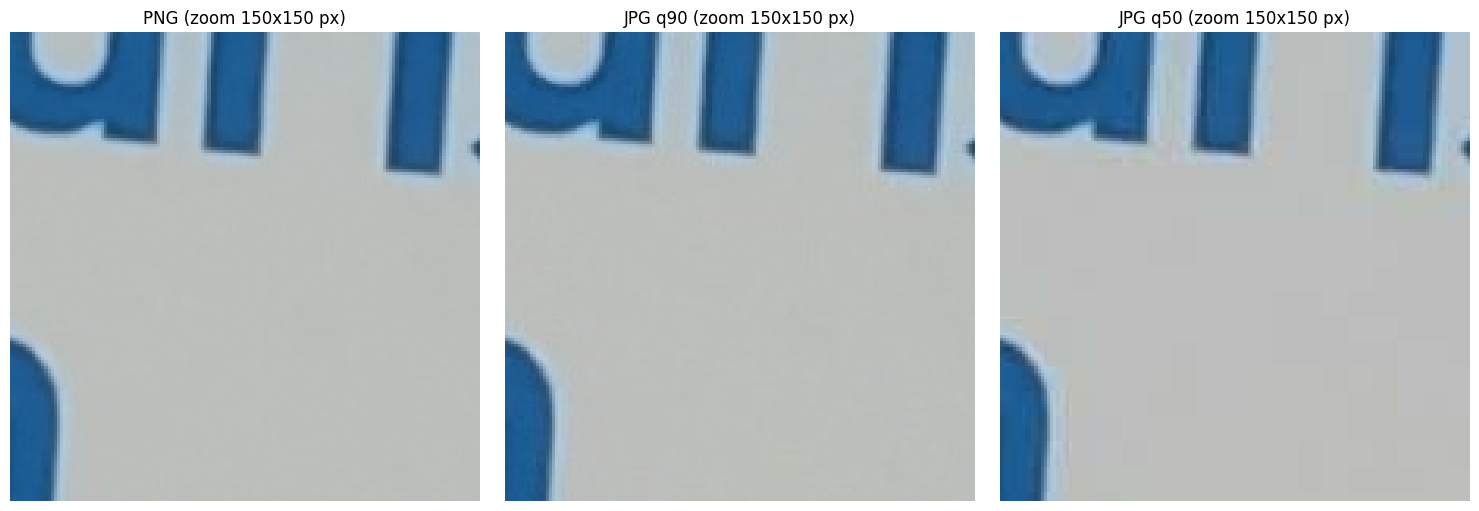

In [9]:
# Zoom a una región para ver artefactos de compresión
h, w = orig.shape[:2]
y0, x0, t = h // 2 - 75, w // 2 - 75, 150
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (t_, r) in zip(axs, [('PNG', 'comparacion.png'), ('JPG q90', 'comparacion.jpg'), ('JPG q50', 'comparacion_q50.jpg')]):
    crop = cv2.imread(r)[y0:y0 + t, x0:x0 + t]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_title(f'{t_} (zoom {t}x{t} px)')
    ax.axis('off')
plt.tight_layout()
plt.savefig('resultados/06_zoom_formatos.png', dpi=150, bbox_inches='tight')
plt.show()

**Análisis.** Con la misma resolución (3000×4000), el PNG pesó 7575.6 KB, el JPG de calidad 90 pesó 921.6 KB (unas 8 veces menos) y el JPG de calidad 50 pesó 298.3 KB (unas 25 veces menos). El PNG usa compresión sin pérdida: la copia es idéntica píxel a píxel al original. El JPG usa compresión con pérdida (transformada DCT y cuantización): descarta información poco perceptible y el PSNR frente al original baja de 50.11 dB (calidad 90) a 43.62 dB (calidad 50). Por eso dos archivos con la misma resolución pueden ocupar espacios muy distintos.

## 4. Tratamiento de una imagen problemática

### 4.1 Problema identificado y decisión técnica
Imagen seleccionada: **Oscura**.

> La imagen presenta **baja iluminación (subexposición)**: brillo medio de 64.6 frente a 134.7 de la referencia, contraste de 49.4 y 41.0 % de píxeles con intensidad menor a 50. Aplicaré **un ajuste lineal de brillo y contraste (`alpha = 1.2`, `beta = 25`)** porque espero mejorar **la exposición de la imagen (brillo medio y rango de intensidades) sin saturar las zonas claras ni amplificar de forma excesiva el ruido**.

In [10]:
# Imagen y tratamiento seleccionados
IMAGEN_A_TRATAR = 'Oscura'
TRATAMIENTO = 'brillo_contraste'

# Parámetros de cada tratamiento considerado
ALPHA, BETA = 1.2, 25        # brillo_contraste (alpha: contraste, beta: brillo)
GAMMA = 0.5                  # gamma < 1 aclara las zonas oscuras
CLIP, TILE = 2.0, (8, 8)     # CLAHE
SIGMA, CANTIDAD = 1.5, 1.0   # unsharp (realce de nitidez)

In [11]:
def aplicar(img, metodo):
    if metodo == 'brillo_contraste':
        return cv2.convertScaleAbs(img, alpha=ALPHA, beta=BETA)
    if metodo == 'gamma':
        tabla = np.array([((i / 255.0) ** GAMMA) * 255 for i in range(256)]).astype('uint8')
        return cv2.LUT(img, tabla)
    if metodo == 'ecualizacion':
        ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
        ycc[:, :, 0] = cv2.equalizeHist(ycc[:, :, 0])
        return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)
    if metodo == 'clahe':
        lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)
        l = cv2.createCLAHE(clipLimit=CLIP, tileGridSize=TILE).apply(l)
        return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
    if metodo == 'unsharp':
        desenf = cv2.GaussianBlur(img, (0, 0), SIGMA)
        return cv2.addWeighted(img, 1 + CANTIDAD, desenf, -CANTIDAD, 0)
    raise ValueError('Tratamiento no reconocido')

antes_img = imagenes[IMAGEN_A_TRATAR]
despues_img = aplicar(antes_img, TRATAMIENTO)
cv2.imwrite('resultados/tratada.jpg', despues_img, [cv2.IMWRITE_JPEG_QUALITY, 95])
print(f'Imagen tratada: {IMAGEN_A_TRATAR} | tratamiento: {TRATAMIENTO}')

Imagen tratada: Oscura | tratamiento: brillo_contraste


### 4.2 Comparación de alternativas
Para sustentar la decisión se aplicaron a la misma imagen otros tratamientos y se compararon sus métricas. El realce de nitidez (`unsharp`) se incluye como contraste: no corrige un problema de exposición.

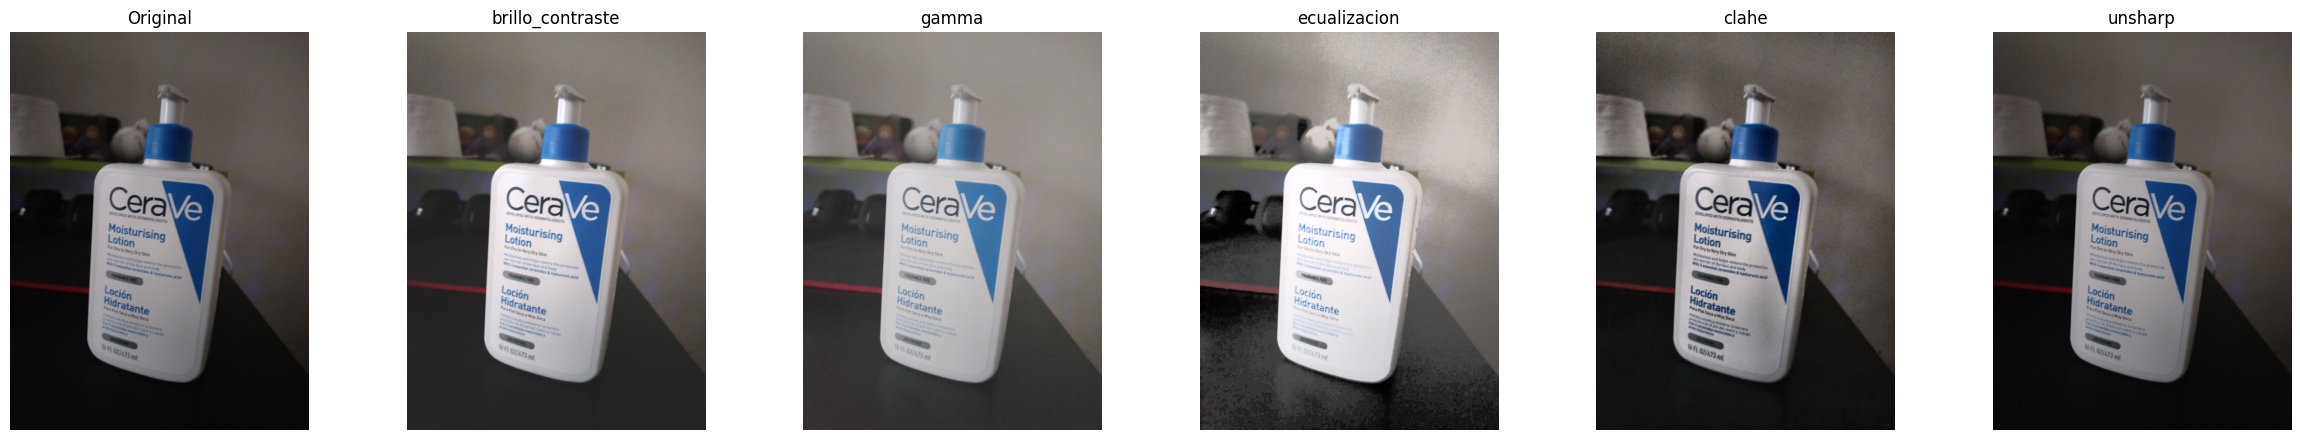

,Brillo,Contraste,Nitidez (800 px),% píxeles oscuros (<50),% píxeles saturados (>=250),Ruido estimado
Original,64.63444,49.3673,62.397946,40.980917,0.0,1.249767
brillo_contraste,102.578911,59.239085,89.162008,31.719783,0.122292,1.523913
gamma,116.300729,52.890034,54.367141,13.790525,0.0,1.339996
ecualizacion,129.842846,71.930308,270.002677,18.967983,2.28915,4.134054
clahe,76.999863,55.063697,189.363791,37.680075,0.0,3.008808
unsharp,64.66222,49.51365,115.803166,41.139842,0.00005,2.47348


In [12]:
alternativas = {'Original': antes_img}
for m in ['brillo_contraste', 'gamma', 'ecualizacion', 'clahe', 'unsharp']:
    alternativas[m] = aplicar(antes_img, m)

df_alt = pd.DataFrame({k: metricas(v) for k, v in alternativas.items()}).T[
    ['Brillo', 'Contraste', 'Nitidez (800 px)', '% píxeles oscuros (<50)',
     '% píxeles saturados (>=250)', 'Ruido estimado']]
df_alt.to_csv('resultados/07_alternativas.csv', encoding='utf-8-sig')

fig, axs = plt.subplots(1, 6, figsize=(24, 4.5))
for ax, (k, v) in zip(axs, alternativas.items()):
    ax.imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax.set_title(k); ax.axis('off')
plt.tight_layout()
plt.savefig('resultados/07_alternativas.png', dpi=130, bbox_inches='tight')
plt.show()
df_alt.round(2)

**Análisis de la comparación**

- **Ecualización de histograma:** alcanza el mayor brillo (129.8) y contraste (71.9), pero satura 2.29 % de los píxeles y multiplica el ruido estimado por 3.3 (de 1.25 a 4.13). El aumento de nitidez (62.4 → 270.0) corresponde en buena parte a ruido amplificado.
- **CLAHE:** multiplica el ruido por 2.4 (3.01) y el brillo apenas llega a 77.0.
- **Gamma (0.5):** es la alternativa más cercana. Reduce los píxeles oscuros a 13.8 % con poco aumento de ruido (1.34), pero mejora poco el contraste (52.9) y la nitidez baja (54.4).
- **Unsharp:** no modifica el brillo (64.7), por lo que no resuelve el problema de exposición.
- **Brillo y contraste (alpha = 1.2, beta = 25):** brillo de 102.6, contraste de 59.2, 0.12 % de píxeles saturados y un aumento moderado del ruido (1.52). Se eligió por ser la mejora más equilibrada del problema identificado (exposición), con una transformación lineal simple de explicar y de reproducir.

## 5. Evaluación antes y después
Se repitieron las métricas sobre la imagen tratada para comprobar si el ajuste mejoró el problema identificado (exposición deficiente).

In [13]:
m_a, m_d = metricas(antes_img), metricas(despues_img)
claves = ['Brillo', 'Contraste', 'Nitidez', 'Nitidez (800 px)', 'Resolución',
          '% píxeles oscuros (<50)', '% píxeles saturados (>=250)', 'Rango dinámico (p99-p1)', 'Ruido estimado']
filas = []
for k in claves:
    a, d = m_a[k], m_d[k]
    if isinstance(a, str):
        cambio = 'sin cambio' if a == d else 'cambió'
    else:
        cambio = f'{(d - a) / a * 100:+.1f} %' if a != 0 else f'{d - a:+.2f}'
    filas.append({'Métrica': k,
                  'Antes': round(a, 2) if not isinstance(a, str) else a,
                  'Después': round(d, 2) if not isinstance(d, str) else d,
                  'Cambio': cambio})
df_ad = pd.DataFrame(filas)
df_ad.to_csv('resultados/08_antes_despues.csv', index=False, encoding='utf-8-sig')
df_ad

,Métrica,Antes,Después,Cambio
0,Brillo,64.63,102.58,+58.7 %
1,Contraste,49.37,59.24,+20.0 %
2,Nitidez,20.27,30.25,+49.2 %
3,Nitidez (800 px),62.4,89.16,+42.9 %
4,Resolución,3000x4000,3000x4000,sin cambio
5,% píxeles oscuros (<50),40.98,31.72,-22.6 %
6,% píxeles saturados (>=250),0.0,0.12,+0.12
7,Rango dinámico (p99-p1),171.0,206.0,+20.5 %
8,Ruido estimado,1.25,1.52,+21.9 %


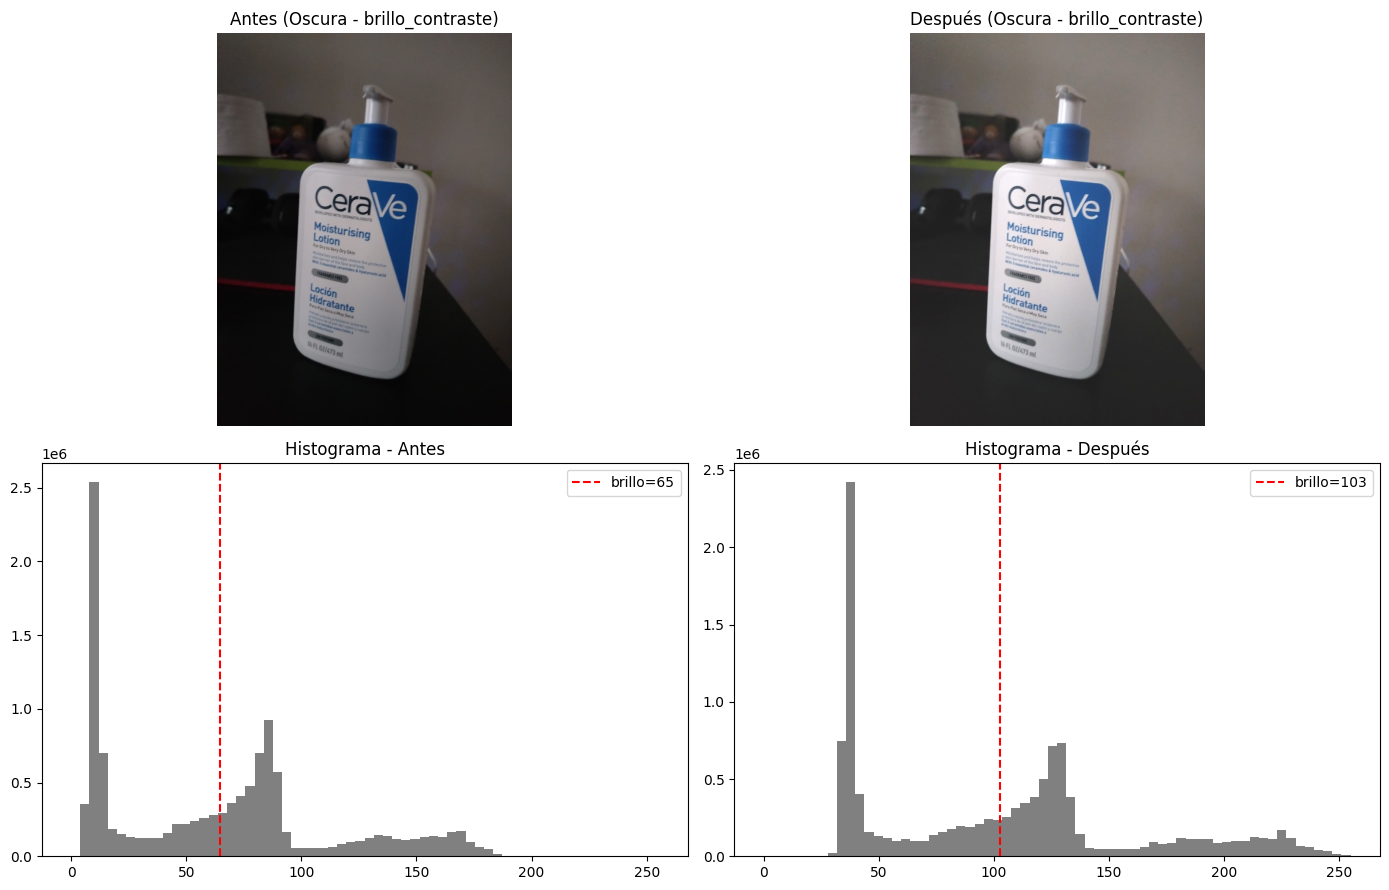

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for col, (t, im) in enumerate([('Antes', antes_img), ('Después', despues_img)]):
    axs[0, col].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    axs[0, col].set_title(f'{t} ({IMAGEN_A_TRATAR} - {TRATAMIENTO})')
    axs[0, col].axis('off')
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    axs[1, col].hist(g.ravel(), bins=64, range=(0, 255), color='gray')
    axs[1, col].axvline(g.mean(), color='red', linestyle='--', label=f'brillo={g.mean():.0f}')
    axs[1, col].set_title(f'Histograma - {t}')
    axs[1, col].legend()
plt.tight_layout()
plt.savefig('resultados/09_antes_despues.png', dpi=150, bbox_inches='tight')
plt.show()

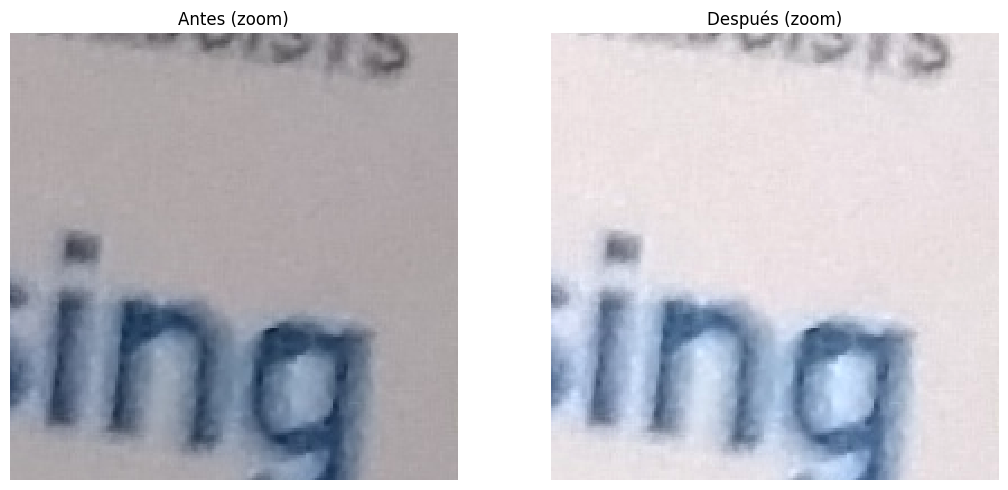

In [15]:
# Zoom al centro para comparar detalle y ruido
h, w = antes_img.shape[:2]
y0, x0, t = h // 2 - 100, w // 2 - 100, 200
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, (n, im) in zip(axs, [('Antes', antes_img), ('Después', despues_img)]):
    ax.imshow(cv2.cvtColor(im[y0:y0 + t, x0:x0 + t], cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_title(f'{n} (zoom)'); ax.axis('off')
plt.tight_layout()
plt.savefig('resultados/10_zoom_antes_despues.png', dpi=150, bbox_inches='tight')
plt.show()

**Análisis de resultados**

- El brillo pasó de 64.6 a 102.6 (+58.7 %) y los píxeles oscuros bajaron de 41.0 % a 31.7 %. El contraste subió de 49.4 a 59.2 (+20.0 %) y el rango dinámico de 171 a 206. La exposición mejoró, pero no alcanzó los valores de la referencia (brillo 134.7, contraste 68.4 y 15.3 % de píxeles oscuros).
- La nitidez aumentó 49.2 % y el ruido estimado 21.9 %. Ambos cambios son cercanos a alpha² = 1.44 y alpha = 1.2: se explican por el escalado de intensidades y no por recuperación de detalle. En el zoom, el texto del envase sigue borroso.
- En el histograma el pico de píxeles oscuros se desplazó de aproximadamente 10 a 35 (efecto de beta), por lo que las zonas negras quedan grises.
- Aparece 0.12 % de píxeles saturados que antes no existían.
- Conclusión: el tratamiento mejora la exposición de forma parcial, sin alcanzar la calidad de la referencia y sin mejorar la relación entre contraste y ruido.

## 6. Resumen de resultados
Resumen impreso de las métricas del diagnóstico y de la evaluación antes/después.

In [16]:
print('OBJETO:', OBJETO)
print('IMAGEN TRATADA:', IMAGEN_A_TRATAR, '| TRATAMIENTO:', TRATAMIENTO)
print()
print('Diagnóstico (Brillo / Contraste / Nitidez 800px):')
for n, m in met.items():
    print(f"  - {n:<17} brillo={m['Brillo']:.1f}  contraste={m['Contraste']:.1f}  nitidez={m['Nitidez (800 px)']:.1f}  res={m['Resolución']}")
print()
print('Antes vs después:')
for _, r in df_ad.iterrows():
    print(f"  - {r['Métrica']:<28} {r['Antes']} -> {r['Después']}  ({r['Cambio']})")

OBJETO: Crema
IMAGEN TRATADA: Oscura | TRATAMIENTO: brillo_contraste

Diagnóstico (Brillo / Contraste / Nitidez 800px):
  - Referencia        brillo=134.7  contraste=68.4  nitidez=276.6  res=3000x4000
  - Oscura            brillo=64.6  contraste=49.4  nitidez=62.4  res=3000x4000
  - Desenfocada       brillo=145.1  contraste=71.2  nitidez=354.7  res=3000x4000
  - Fondo complejo    brillo=127.0  contraste=76.9  nitidez=197.5  res=3000x4000
  - Otra perspectiva  brillo=147.5  contraste=62.2  nitidez=129.3  res=3000x4000

Antes vs después:
  - Brillo                       64.63 -> 102.58  (+58.7 %)
  - Contraste                    49.37 -> 59.24  (+20.0 %)
  - Nitidez                      20.27 -> 30.25  (+49.2 %)
  - Nitidez (800 px)             62.4 -> 89.16  (+42.9 %)
  - Resolución                   3000x4000 -> 3000x4000  (sin cambio)
  - % píxeles oscuros (<50)      40.98 -> 31.72  (-22.6 %)
  - % píxeles saturados (>=250)  0.0 -> 0.12  (+0.12)
  - Rango dinámico (p99-p1)      171.0 

## 7. Exportación de resultados
Las tablas y figuras generadas se empaquetan en `resultados_s8.zip` para incluirlas en el informe.

In [17]:
shutil.make_archive('resultados_s8', 'zip', 'resultados')
print('Generado: resultados_s8.zip')
if EN_COLAB:
    files.download('resultados_s8.zip')

Generado: resultados_s8.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones

- El diagnóstico de una imagen requiere combinar métricas con inspección visual: el desenfoque y el fondo complejo no se reflejaron en las métricas globales como se esperaba.
- La subexposición sí fue medible (brillo, contraste y porcentaje de píxeles oscuros) y permitió justificar un tratamiento concreto.
- El ajuste de brillo y contraste mejoró la exposición de forma parcial, pero no recuperó detalle ni mejoró la relación entre contraste y ruido; hay problemas, como el desenfoque, que el procesamiento no corrige.
- Limitación: la nitidez se midió de forma global; una medición sobre la región del objeto sería más confiable.